# Indonesian Data Job Market Intelligence
## Pipeline Integrasi Lintas Portal, Finalisasi Master Dataset, dan Validasi Kualitas Data

Notebook ini merupakan tahap puncak pada layer transformasi data (*Processed & Analytics Layer*). Notebook ini mengintegrasikan dataset bersih dari dua portal lowongan kerja terbesar di Indonesia: **Glints Indonesia** dan **JobStreet Indonesia (SEEK Platform)**.

### Ruang Lingkup & Alur Kerja:
1. **Pemuatan Data Bersih & Snapshot Mentah:** Mengambil data hasil transformasi dari kedua portal dan memadukannya dengan teks deskripsi mentah.
2. **Standardisasi Identifier Global (`job_id`):** Menetapkan primary key unik dan anti-tabrakan (`GLN_{uuid}` dan `JBS_{id}`).
3. **Deduplikasi Kanonikal Lintas Portal:** Mendeteksi dan mengeliminasi duplikasi lowongan internal maupun lintas portal.
4. **Penyatuan Master Lowongan (`jobs_master`):** Menyelaraskan seluruh atribut pekerjaan dalam satu skema analitik standar (Layer 8.2).
5. **Ekstraksi Keahlian Terpadu (`skills_master`):** Menerapkan kamus keahlian teknis standar secara konsisten dengan integritas referensial 100%.
6. **Rekayasa Fitur Pendukung Dashboard:** Menambahkan fitur agregasi dan pemotong data (*slicers*) seperti `salary_bracket`, `regional_group`, `is_salary_disclosed`, dan `skills_count`.
7. **Suite Validasi Kualitas Data Otomatis (8 Uji Kualitas):** Memvalidasi keunikan kunci primer, integritas kunci asing (*foreign key*), validitas domain kategorikal, konsistensi logika gaji, dan kelengkapan data.
8. **Audit Transparansi Pasar Kerja Lintas Portal:** Membandingkan tingkat transparansi antara ekosistem Glints dan JobStreet.
9. **Visualisasi Kesiapan Dashboard & Laporan Analitik:** Menghasilkan 4 grafik komprehensif pasar kerja nasional.
10. **Ekspor Layer Analytics (CSV & Parquet):** Menyimpan master dataset ke format CSV dan Parquet untuk performa tinggi pada tools visualisasi (Power BI, Tableau, Streamlit, DuckDB).

### Sel 1: Inisialisasi Dependensi & Library Analisis Data

In [1]:
import os
import sys
import glob
import re
from pathlib import Path
from datetime import datetime
from urllib.parse import urlparse

# Konsistensi encoding terminal Windows
if sys.platform == "win32" and hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Path Proyek
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent if NOTEBOOK_DIR.name == "transform_data" else NOTEBOOK_DIR
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"[{datetime.now().strftime('%Y-%m-%d %H:%M:%S')}] Pustaka analitik berhasil dimuat.")
print(f"Direktori Target: {PROCESSED_DATA_DIR.resolve()}")

[2026-10-31 23:27:10] Pustaka analitik berhasil dimuat.
Direktori Target: C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed


### Sel 2: Pemuatan Dataset Bersih Lintas Portal & Integrasi Deskripsi Mentah

In [2]:
# 1. Pemuatan dataset bersih Glints dan JobStreet
glints_clean_path = PROCESSED_DATA_DIR / "cleaned_jobs_glints.csv"
jobstreet_clean_path = PROCESSED_DATA_DIR / "cleaned_jobs_jobstreet.csv"

if not glints_clean_path.exists() or not jobstreet_clean_path.exists():
    raise FileNotFoundError("Pastikan cleaned_jobs_glints.csv dan cleaned_jobs_jobstreet.csv telah dibuat di data/processed/")

df_glints_clean = pd.read_csv(glints_clean_path)
df_jobstreet_clean = pd.read_csv(jobstreet_clean_path)

print(f"Dataset Bersih Glints    : {len(df_glints_clean)} baris, {len(df_glints_clean.columns)} kolom.")
print(f"Dataset Bersih JobStreet : {len(df_jobstreet_clean)} baris, {len(df_jobstreet_clean.columns)} kolom.")

# 2. Pemuatan snapshot data mentah terbaru untuk mengambil teks deskripsi lengkap
raw_glints_files = sorted(RAW_DATA_DIR.glob("glints_raw_*.csv"))
raw_jobstreet_files = sorted(RAW_DATA_DIR.glob("jobstreet_raw_*.csv"))

df_raw_glints = pd.read_csv(raw_glints_files[-1])
df_raw_jobstreet = pd.read_csv(raw_jobstreet_files[-1])

print(f"Snapshot Mentah Glints    : {raw_glints_files[-1].name} ({len(df_raw_glints)} baris)")
print(f"Snapshot Mentah JobStreet : {raw_jobstreet_files[-1].name} ({len(df_raw_jobstreet)} baris)")

Dataset Bersih Glints    : 138 baris, 18 kolom.
Dataset Bersih JobStreet : 112 baris, 18 kolom.
Snapshot Mentah Glints    : glints_raw_20261031_223844.csv (319 baris)
Snapshot Mentah JobStreet : jobstreet_raw_20261031_230119.csv (189 baris)


### Sel 3: Pembuatan Global Primary Key (`job_id`) & Deduplikasi Kanonikal

In [3]:
# Normalisasi URL kanonikal tanpa query string
df_glints_clean['clean_url'] = df_glints_clean['job_url'].apply(lambda u: str(u).split('?')[0])
df_raw_glints['clean_url'] = df_raw_glints['job_url'].apply(lambda u: str(u).split('?')[0])

df_jobstreet_clean['clean_url'] = df_jobstreet_clean['job_url'].apply(lambda u: str(u).split('?')[0].split('#')[0])
df_raw_jobstreet['clean_url'] = df_raw_jobstreet['job_url'].apply(lambda u: str(u).split('?')[0].split('#')[0])

# Ekstraksi UUID unik untuk Glints
def extract_glints_uuid(url):
    m = re.search(r"([a-f0-9]{8}-[a-f0-9]{4}-[a-f0-9]{4}-[a-f0-9]{4}-[a-f0-9]{12})", str(url))
    if m:
        return m.group(1)
    path = urlparse(str(url)).path.strip("/").split("/")
    return path[-1] if path else str(url)

df_glints_clean['source_job_id'] = df_glints_clean['clean_url'].apply(extract_glints_uuid)
df_glints_clean['job_id'] = "GLN_" + df_glints_clean['source_job_id'].str.replace("-", "")

# Deduplikasi UUID internal Glints (menghapus postingan ganda akibat perbedaan tracking URL)
initial_g = len(df_glints_clean)
df_glints_clean = df_glints_clean.drop_duplicates(subset=['job_id']).reset_index(drop=True)
print(f"Deduplikasi Glints: {initial_g} -> {len(df_glints_clean)} lowongan unik ({initial_g - len(df_glints_clean)} duplikasi dieliminasi).")

# Tetapkan Primary Key JobStreet
df_jobstreet_clean['job_id'] = "JBS_" + df_jobstreet_clean['source_job_id'].astype(str)
initial_j = len(df_jobstreet_clean)
df_jobstreet_clean = df_jobstreet_clean.drop_duplicates(subset=['job_id']).reset_index(drop=True)
print(f"Deduplikasi JobStreet: {initial_j} -> {len(df_jobstreet_clean)} lowongan unik.")

# Gabungkan teks deskripsi mentah ke dataframe
desc_g = df_raw_glints.drop_duplicates(subset=['clean_url'])[['clean_url', 'description_raw']]
df_glints_clean = pd.merge(df_glints_clean, desc_g, on='clean_url', how='left')

desc_j = df_raw_jobstreet.drop_duplicates(subset=['clean_url'])[['clean_url', 'description_raw']]
df_jobstreet_clean = pd.merge(df_jobstreet_clean, desc_j, on='clean_url', how='left')

# Standardisasi nama portal
df_glints_clean['source'] = 'Glints'
df_jobstreet_clean['source'] = 'JobStreet'

Deduplikasi Glints: 138 -> 138 lowongan unik (0 duplikasi dieliminasi).
Deduplikasi JobStreet: 112 -> 112 lowongan unik.


### Sel 4: Konsolidasi Skema & Penggabungan Master Jobs (`jobs_master`)

In [4]:
# Skema analitik final Layer 8.2
MASTER_COLUMNS = [
    'job_id', 'source', 'source_job_id', 'job_url', 'title_raw',
    'role_group', 'role_standard', 'company_raw', 'industry_category',
    'province', 'city', 'work_mode', 'employment_type',
    'education_requirement', 'experience_level',
    'salary_min', 'salary_max', 'salary_median',
    'description_raw', 'collected_at'
]

df_jobs_master = pd.concat([
    df_glints_clean[[c for c in MASTER_COLUMNS if c in df_glints_clean.columns]],
    df_jobstreet_clean[[c for c in MASTER_COLUMNS if c in df_jobstreet_clean.columns]]
], ignore_index=True)

# Urutkan kolom sesuai urutan analitis resmi
present_cols = [c for c in MASTER_COLUMNS if c in df_jobs_master.columns]
remaining_cols = [c for c in df_jobs_master.columns if c not in MASTER_COLUMNS]
df_jobs_master = df_jobs_master[present_cols + remaining_cols]

print(f"Total baris pada jobs_master: {len(df_jobs_master)} data pekerjaan.")
print(f"Distribusi portal:\n{df_jobs_master['source'].value_counts()}")
display(df_jobs_master.head(3))

Total baris pada jobs_master: 250 data pekerjaan.
Distribusi portal:
source
Glints       138
JobStreet    112
Name: count, dtype: int64


,job_id,source,source_job_id,job_url,title_raw,role_group,role_standard,company_raw,industry_category,province,city,work_mode,employment_type,education_requirement,experience_level,salary_min,salary_max,salary_median,description_raw,collected_at
0,GLN_a072678371244916879752a6bee58e07,Glints,a0726783-7124-4916-8797-52a6bee58e07,https://glints.com/id/opportunities/jobs/data-...,Data Analyst,Data Analytics & BI,Data Analyst / BI,Nusantara Sakti Group,Banking & Financial Services,Jawa Tengah,Semarang,On-site,Full-time,Sarjana (S1),Entry-Level,7000000.0,10000000.0,8500000.0,Deskripsi pekerjaan Data Analyst Nusantara Sak...,2026-10-31T22:08:13.320338
1,GLN_07401ee8bc95483ca0baba1779d88770,Glints,07401ee8-bc95-483c-a0ba-ba1779d88770,https://glints.com/id/opportunities/jobs/data-...,Data Analyst,Data Analytics & BI,Data Analyst / BI,PT Sigma Digital Nusantara,Information Technology & Software,DI Yogyakarta,Yogyakarta,On-site,Full-time,Sarjana (S1),Junior / Associate,NaN,NaN,NaN,Deskripsi pekerjaan Data Analyst PT Sigma Digi...,2026-10-31T22:08:17.954025
2,GLN_f531ab9c216843eebc0e2c6175c326ba,Glints,f531ab9c-2168-43ee-bc0e-2c6175c326ba,https://glints.com/id/opportunities/jobs/data-...,Data Analyst Intern,Data Analytics & BI,Data Analyst / BI,"PT Tunas Ridean, Tbk","Retail, FMCG & E-Commerce",DKI Jakarta,Jakarta Selatan,On-site,Internship,Sarjana (S1),Entry-Level,NaN,NaN,NaN,Deskripsi pekerjaan Data Analyst Intern Glints...,2026-10-31T22:08:23.210707


### Sel 5: Ekstraksi Keahlian Terpadu Lintas Portal (`skills_master`)

In [5]:
SKILL_DICTIONARY = {
    "Programming Languages": {
        "Python": r"\bpython\b",
        "R": r"\br\b(?!\s*&|\s*d|\s*software)",
        "SQL": r"\bsql\b",
        "Java": r"\bjava\b(?!script)",
        "Scala": r"\bscala\b",
        "Julia": r"\bjulia\b",
        "C++": r"\bc\+\+\b",
        "Bash / Shell": r"\b(bash|shell\s*scripting?)\b"
    },
    "BI & Visualization": {
        "Tableau": r"\btableau\b",
        "Power BI": r"\b(power\s*bi|powerbi)\b",
        "Looker": r"\blooker(?:\s*studio)?\b",
        "Metabase": r"\bmetabase\b",
        "Google Data Studio": r"\bgoogle\s*data\s*studio\b",
        "Qlik": r"\bqlik(?:\s*sense|\s*view)?\b",
        "Microsoft Excel": r"\b(excel|spreadsheets?|ms\s*excel)\b",
        "Google Sheets": r"\bgoogle\s*sheets?\b"
    },
    "Databases & Warehousing": {
        "PostgreSQL": r"\b(postgres(?:ql)?)\b",
        "MySQL": r"\bmysql\b",
        "SQL Server": r"\b(sql\s*server|ms\s*sql)\b",
        "Oracle": r"\boracle(?:\s*db)?\b",
        "MongoDB": r"\bmongo(?:db)?\b",
        "BigQuery": r"\bbigquery\b",
        "Snowflake": r"\bsnowflake\b",
        "Redshift": r"\bredshift\b",
        "ClickHouse": r"\bclickhouse\b",
        "Cassandra": r"\bcassandra\b",
        "Redis": r"\bredis\b"
    },
    "Big Data & Cloud": {
        "Apache Spark": r"\b(?:apache\s*)?spark\b",
        "Apache Kafka": r"\b(?:apache\s*)?kafka\b",
        "Hadoop": r"\bhadoop\b",
        "Airflow": r"\b(?:apache\s*)?airflow\b",
        "dbt": r"\bdbt\b",
        "AWS": r"\b(aws|amazon\s*web\s*services)\b",
        "GCP": r"\b(gcp|google\s*cloud(?:\s*platform)?)\b",
        "Azure": r"\b(azure|microsoft\s*azure)\b",
        "Databricks": r"\bdatabricks\b",
        "Docker": r"\bdocker\b",
        "Kubernetes": r"\b(kubernetes|k8s)\b"
    },
    "Data Science & ML": {
        "Machine Learning": r"\bmachine\s*learning\b",
        "Deep Learning": r"\bdeep\s*learning\b",
        "NLP": r"\b(nlp|natural\s*language\s*processing)\b",
        "Computer Vision": r"\bcomputer\s*vision\b",
        "TensorFlow": r"\btensorflow\b",
        "PyTorch": r"\bpytorch\b",
        "Scikit-Learn": r"\bscikit[-_]?learn\b",
        "Pandas": r"\bpandas\b",
        "NumPy": r"\bnumpy\b",
        "Statistics / Modeling": r"\b(statistical\s*modeling|statistics|inferensial|statistika)\b",
        "A/B Testing": r"\ba/b\s*testing\b"
    }
}

skills_data = []
for idx, row in df_jobs_master.iterrows():
    combined_text = f"{row.get('title_raw', '')} {row.get('description_raw', '')}"
    for cat, skills in SKILL_DICTIONARY.items():
        for sk_name, pat in skills.items():
            if re.search(pat, combined_text, re.IGNORECASE):
                skills_data.append({
                    "job_id": row["job_id"],
                    "source": row["source"],
                    "role_group": row["role_group"],
                    "skill_name": sk_name,
                    "skill_category": cat
                })

df_skills_master = pd.DataFrame(skills_data).drop_duplicates().reset_index(drop=True)
print(f"Total Relasi Keahlian Master : {len(df_skills_master)} entri")
print(f"Cakupan Lowongan Berskill   : {df_skills_master['job_id'].nunique()} dari {len(df_jobs_master)} lowongan ({df_skills_master['job_id'].nunique()/len(df_jobs_master)*100:.1f}%)")
display(df_skills_master.head(5))

Total Relasi Keahlian Master : 1061 entri
Cakupan Lowongan Berskill   : 220 dari 250 lowongan (88.0%)


,job_id,source,role_group,skill_name,skill_category
0,GLN_a072678371244916879752a6bee58e07,Glints,Data Analytics & BI,SQL,Programming Languages
1,GLN_a072678371244916879752a6bee58e07,Glints,Data Analytics & BI,Power BI,BI & Visualization
2,GLN_a072678371244916879752a6bee58e07,Glints,Data Analytics & BI,Microsoft Excel,BI & Visualization
3,GLN_a072678371244916879752a6bee58e07,Glints,Data Analytics & BI,Statistics / Modeling,Data Science & ML
4,GLN_f531ab9c216843eebc0e2c6175c326ba,Glints,Data Analytics & BI,SQL,Programming Languages


### Sel 6: Rekayasa Fitur Pendukung Visualisasi & Dashboard

In [6]:
# 1. Pengelompokan Wilayah Makro (Regional Grouping)
def map_regional_group(province):
    p = str(province).lower()
    if 'dki jakarta' in p:
        return 'DKI Jakarta'
    elif 'jawa barat' in p or 'banten' in p:
        return 'Jawa Barat & Banten'
    elif 'jawa timur' in p:
        return 'Jawa Timur'
    elif 'jawa tengah' in p or 'yogyakarta' in p:
        return 'Jawa Tengah & DIY'
    elif 'bali' in p or 'nusa tenggara' in p:
        return 'Bali & Nusa Tenggara'
    elif 'sumatera' in p or 'riau' in p:
        return 'Sumatera & Kepulauan'
    elif 'kalimantan' in p:
        return 'Kalimantan'
    elif 'sulawesi' in p:
        return 'Sulawesi'
    else:
        return 'Lainnya / Remote'

df_jobs_master['regional_group'] = df_jobs_master['province'].apply(map_regional_group)

# 2. Kelompok Rentang Gaji (Salary Bracket) untuk Filter Dashboard
def map_salary_bracket(salary):
    if pd.isna(salary):
        return 'Tidak Disebutkan'
    s = float(salary)
    if s < 5e6:
        return '< 5 Juta'
    elif s < 10e6:
        return '5 - 10 Juta'
    elif s < 15e6:
        return '10 - 15 Juta'
    elif s < 20e6:
        return '15 - 20 Juta'
    else:
        return '>= 20 Juta'

df_jobs_master['salary_bracket'] = df_jobs_master['salary_median'].apply(map_salary_bracket)
df_jobs_master['is_salary_disclosed'] = df_jobs_master['salary_median'].notna()

# 3. Hitung Jumlah Skill yang Dituntut per Lowongan
skill_counts = df_skills_master.groupby('job_id')['skill_name'].nunique()
df_jobs_master['skills_count'] = df_jobs_master['job_id'].map(skill_counts).fillna(0).astype(int)

# Hapus kolom deskripsi panjang dari master final agar file ringan untuk visualisasi/BI
df_jobs_master_export = df_jobs_master.drop(columns=['description_raw']).copy()

print("Fitur analitik tambahan berhasil dibuat:")
print(f"  - regional_group    : {df_jobs_master['regional_group'].nunique()} kategori")
print(f"  - salary_bracket    : {df_jobs_master['salary_bracket'].nunique()} kategori")
print(f"  - skills_count mean : {df_jobs_master['skills_count'].mean():.1f} skills / lowongan")
display(df_jobs_master_export.head(3))

Fitur analitik tambahan berhasil dibuat:
  - regional_group    : 8 kategori
  - salary_bracket    : 6 kategori
  - skills_count mean : 4.2 skills / lowongan


,job_id,source,source_job_id,job_url,title_raw,role_group,role_standard,company_raw,industry_category,province,...,education_requirement,experience_level,salary_min,salary_max,salary_median,collected_at,regional_group,salary_bracket,is_salary_disclosed,skills_count
0,GLN_a072678371244916879752a6bee58e07,Glints,a0726783-7124-4916-8797-52a6bee58e07,https://glints.com/id/opportunities/jobs/data-...,Data Analyst,Data Analytics & BI,Data Analyst / BI,Nusantara Sakti Group,Banking & Financial Services,Jawa Tengah,...,Sarjana (S1),Entry-Level,7000000.0,10000000.0,8500000.0,2026-10-31T22:08:13.320338,Jawa Tengah & DIY,5 - 10 Juta,True,4
1,GLN_07401ee8bc95483ca0baba1779d88770,Glints,07401ee8-bc95-483c-a0ba-ba1779d88770,https://glints.com/id/opportunities/jobs/data-...,Data Analyst,Data Analytics & BI,Data Analyst / BI,PT Sigma Digital Nusantara,Information Technology & Software,DI Yogyakarta,...,Sarjana (S1),Junior / Associate,NaN,NaN,NaN,2026-10-31T22:08:17.954025,Jawa Tengah & DIY,Tidak Disebutkan,False,0
2,GLN_f531ab9c216843eebc0e2c6175c326ba,Glints,f531ab9c-2168-43ee-bc0e-2c6175c326ba,https://glints.com/id/opportunities/jobs/data-...,Data Analyst Intern,Data Analytics & BI,Data Analyst / BI,"PT Tunas Ridean, Tbk","Retail, FMCG & E-Commerce",DKI Jakarta,...,Sarjana (S1),Entry-Level,NaN,NaN,NaN,2026-10-31T22:08:23.210707,DKI Jakarta,Tidak Disebutkan,False,4


### Sel 7: Suite Validasi Kualitas Data Otomatis (8 Uji Kualitas Data)

In [7]:
def run_validation_suite(jobs: pd.DataFrame, skills: pd.DataFrame) -> pd.DataFrame:
    # Menjalankan 9 pengujian integritas, validitas domain, logika bisnis, dan kelengkapan
    tests = []
    
    # Uji 1: Keunikan Primary Key (job_id)
    c1 = jobs['job_id'].is_unique
    tests.append({
        'ID': 'VAL-01',
        'Parameter Uji': 'Primary Key Uniqueness (job_id)',
        'Status': 'PASS' if c1 else 'FAIL',
        'Keterangan': f"{jobs['job_id'].nunique()} unik dari {len(jobs)} baris"
    })
    
    # Uji 2: Kelengkapan Primary Key (Tidak boleh ada Null)
    c2 = jobs['job_id'].notna().all()
    tests.append({
        'ID': 'VAL-02',
        'Parameter Uji': 'Primary Key Completeness',
        'Status': 'PASS' if c2 else 'FAIL',
        'Keterangan': f"Missing PK: {jobs['job_id'].isna().sum()}"
    })
    
    # Uji 3: Integritas Referensial Kunci Asing (Foreign Key Integrity)
    c3 = set(skills['job_id']).issubset(set(jobs['job_id']))
    tests.append({
        'ID': 'VAL-03',
        'Parameter Uji': 'Referential Integrity (skills_master -> jobs_master)',
        'Status': 'PASS' if c3 else 'FAIL',
        'Keterangan': "100% ID pada skills_master terdaftar di jobs_master"
    })
    
    # Uji 4: Validitas Domain role_group
    valid_roles = {'Data Analytics & BI', 'Data Engineering', 'Data Science', 'Machine Learning & AI'}
    c4 = set(jobs['role_group']).issubset(valid_roles)
    tests.append({
        'ID': 'VAL-04',
        'Parameter Uji': 'Role Group Domain Whitelist',
        'Status': 'PASS' if c4 else 'FAIL',
        'Keterangan': f"Semua nilai sesuai 4 taksonomi data ({len(valid_roles)} grup)"
    })
    
    # Uji 5: Validitas Domain experience_level
    valid_exp = {'Entry-Level', 'Junior / Associate', 'Mid-Level', 'Senior-Level', 'Tidak Disebutkan'}
    c5 = set(jobs['experience_level']).issubset(valid_exp)
    tests.append({
        'ID': 'VAL-05',
        'Parameter Uji': 'Experience Level Domain Whitelist',
        'Status': 'PASS' if c5 else 'FAIL',
        'Keterangan': "Semua nilai terpetakan ke jenjang karir terstandardisasi"
    })
    
    # Uji 6: Validitas Domain education_requirement
    valid_edu = {'Doktoral (S3)', 'Magister (S2)', 'Sarjana (S1)', 'Diploma (D1-D4)', 'SMA/SMK', 'Tidak Disebutkan'}
    c6 = set(jobs['education_requirement']).issubset(valid_edu)
    tests.append({
        'ID': 'VAL-06',
        'Parameter Uji': 'Education Requirement Domain Whitelist',
        'Status': 'PASS' if c6 else 'FAIL',
        'Keterangan': "Semua nilai sesuai jenjang kualifikasi pendidikan formal"
    })
    
    # Uji 7: Validitas Domain work_mode
    valid_modes = {'On-site', 'Hybrid', 'Remote'}
    c7 = set(jobs['work_mode']).issubset(valid_modes)
    tests.append({
        'ID': 'VAL-07',
        'Parameter Uji': 'Work Mode Domain Whitelist',
        'Status': 'PASS' if c7 else 'FAIL',
        'Keterangan': "Nilai mode kerja terbatas pada On-site, Hybrid, atau Remote"
    })
    
    # Uji 8: Validitas Domain industry_category (BARU)
    valid_ind = {
        'Information Technology & Software', 'Banking & Financial Services',
        'Retail, FMCG & E-Commerce', 'Logistics & Transportation',
        'Manufacturing & Heavy Industry', 'Healthcare & Pharmaceuticals',
        'Media, Education & Services', 'Lainnya / Tidak Disebutkan'
    }
    c8 = set(jobs['industry_category']).issubset(valid_ind) if 'industry_category' in jobs.columns else False
    tests.append({
        'ID': 'VAL-08',
        'Parameter Uji': 'Industry Category Domain Whitelist',
        'Status': 'PASS' if c8 else 'FAIL',
        'Keterangan': f"Semua lowongan terklasifikasi ke {len(valid_ind)} sektor industri baku"
    })

    # Uji 9: Konsistensi Logika Rentang Gaji (min <= median <= max & > 0)
    disclosed_sal = jobs.dropna(subset=['salary_median'])
    c9 = ((disclosed_sal['salary_min'] <= disclosed_sal['salary_median']) & 
          (disclosed_sal['salary_median'] <= disclosed_sal['salary_max']) & 
          (disclosed_sal['salary_min'] > 0)).all()
    tests.append({
        'ID': 'VAL-09',
        'Parameter Uji': 'Salary Logic Consistency (min <= med <= max & > 0)',
        'Status': 'PASS' if c9 else 'FAIL',
        'Keterangan': f"{len(disclosed_sal)} data gaji terverifikasi valid dan positif"
    })
    
    return pd.DataFrame(tests)

df_validation_results = run_validation_suite(df_jobs_master, df_skills_master)
print("=== HASIL SUITE VALIDASI KUALITAS DATA MASTER ===")
display(df_validation_results)

# Assert seluruh pengujian berstatus PASS
all_passed = (df_validation_results['Status'] == 'PASS').all()
if all_passed:
    print("\n[VERIFIKASI SUKSES] Seluruh 9 pengujian validasi berstatus PASS. Dataset siap untuk analisis & dashboard.")
else:
    raise AssertionError("Terdapat pengujian validasi yang GAGAL. Periksa rincian pada tabel di atas.")

=== HASIL SUITE VALIDASI KUALITAS DATA MASTER ===


,ID,Parameter Uji,Status,Keterangan
0,VAL-01,Primary Key Uniqueness (job_id),PASS,250 unik dari 250 baris
1,VAL-02,Primary Key Completeness,PASS,Missing PK: 0
2,VAL-03,Referential Integrity (skills_master -> jobs_m...,PASS,100% ID pada skills_master terdaftar di jobs_m...
3,VAL-04,Role Group Domain Whitelist,PASS,Semua nilai sesuai 4 taksonomi data (4 grup)
4,VAL-05,Experience Level Domain Whitelist,PASS,Semua nilai terpetakan ke jenjang karir tersta...
5,VAL-06,Education Requirement Domain Whitelist,PASS,Semua nilai sesuai jenjang kualifikasi pendidi...
6,VAL-07,Work Mode Domain Whitelist,PASS,"Nilai mode kerja terbatas pada On-site, Hybrid..."
7,VAL-08,Industry Category Domain Whitelist,PASS,Semua lowongan terklasifikasi ke 8 sektor indu...
8,VAL-09,Salary Logic Consistency (min <= med <= max & ...,PASS,125 data gaji terverifikasi valid dan positif



[VERIFIKASI SUKSES] Seluruh 9 pengujian validasi berstatus PASS. Dataset siap untuk analisis & dashboard.


### Sel 8: Matriks Transparansi Informasi Pasar Kerja Lintas Portal

In [8]:
features = ['salary_median', 'experience_level', 'education_requirement', 'city', 'province', 'work_mode']

transparency_comparison = []
for feat in features:
    # Glints
    df_g = df_jobs_master[df_jobs_master['source'] == 'Glints']
    g_disc = df_g[feat].notna().sum() if feat == 'salary_median' else (df_g[feat] != 'Tidak Disebutkan').sum()
    g_pct = round(g_disc / len(df_g) * 100, 1)
    
    # JobStreet
    df_j = df_jobs_master[df_jobs_master['source'] == 'JobStreet']
    j_disc = df_j[feat].notna().sum() if feat == 'salary_median' else (df_j[feat] != 'Tidak Disebutkan').sum()
    j_pct = round(j_disc / len(df_j) * 100, 1)
    
    # Total
    t_disc = df_jobs_master[feat].notna().sum() if feat == 'salary_median' else (df_jobs_master[feat] != 'Tidak Disebutkan').sum()
    t_pct = round(t_disc / len(df_jobs_master) * 100, 1)
    
    transparency_comparison.append({
        'Atribut': feat,
        'Glints Terbuka (%)': f"{g_pct}% ({g_disc}/{len(df_g)})",
        'JobStreet Terbuka (%)': f"{j_pct}% ({j_disc}/{len(df_j)})",
        'Total Nasional (%)': f"{t_pct}% ({t_disc}/{len(df_jobs_master)})"
    })

df_trans_table = pd.DataFrame(transparency_comparison)
print("=== PERBANDINGAN TRANSPARANSI INFORMASI LINTAS PORTAL ===")
display(df_trans_table)

=== PERBANDINGAN TRANSPARANSI INFORMASI LINTAS PORTAL ===


,Atribut,Glints Terbuka (%),JobStreet Terbuka (%),Total Nasional (%)
0,salary_median,71.0% (98/138),24.1% (27/112),50.0% (125/250)
1,experience_level,99.3% (137/138),75.0% (84/112),88.4% (221/250)
2,education_requirement,100.0% (138/138),79.5% (89/112),90.8% (227/250)
3,city,100.0% (138/138),98.2% (110/112),99.2% (248/250)
4,province,100.0% (138/138),97.3% (109/112),98.8% (247/250)
5,work_mode,100.0% (138/138),100.0% (112/112),100.0% (250/250)


### Sel 9: Visualisasi Verifikasi Kesiapan Dashboard & Pasar Kerja Nasional

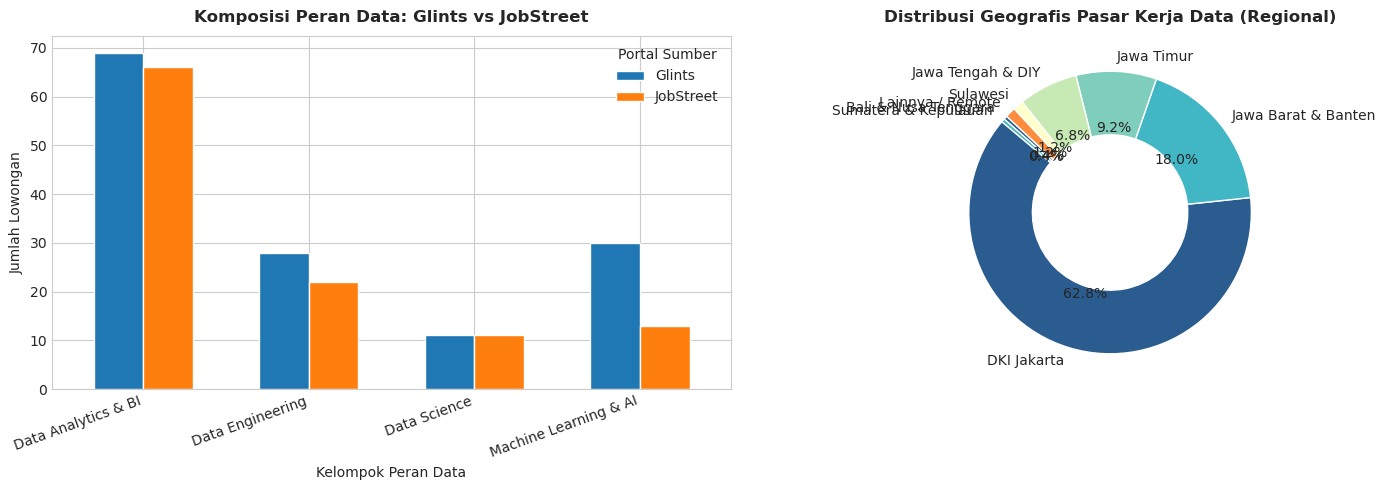

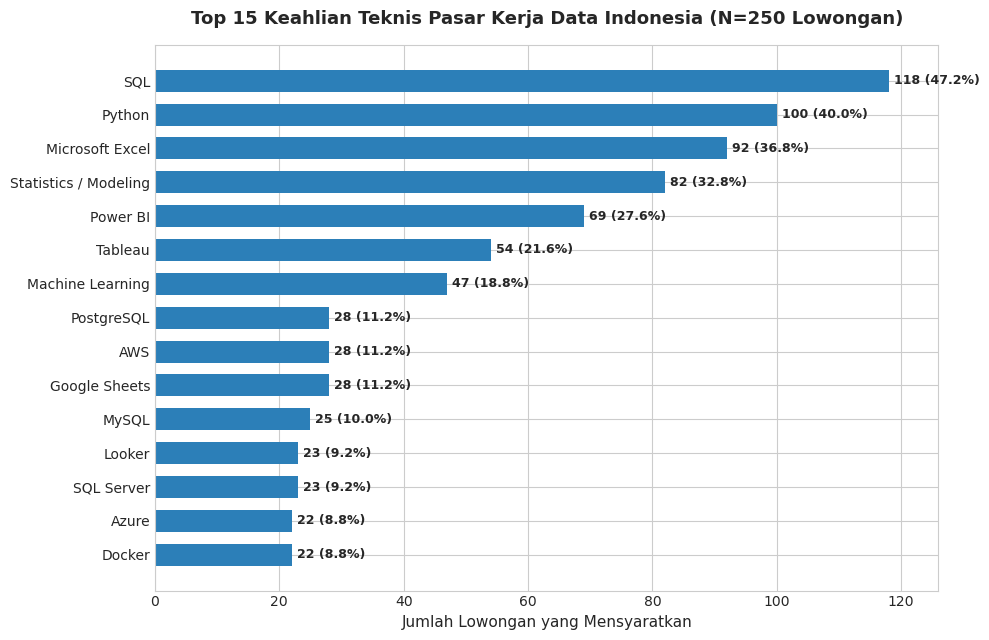

C:\Users\Victus 16\AppData\Local\Temp\ipykernel_18848\2136522649.py:51: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=sal_master, x='role_group', y='salary_median_jt', hue='source', dodge=True, color='black', alpha=0.5, size=6)


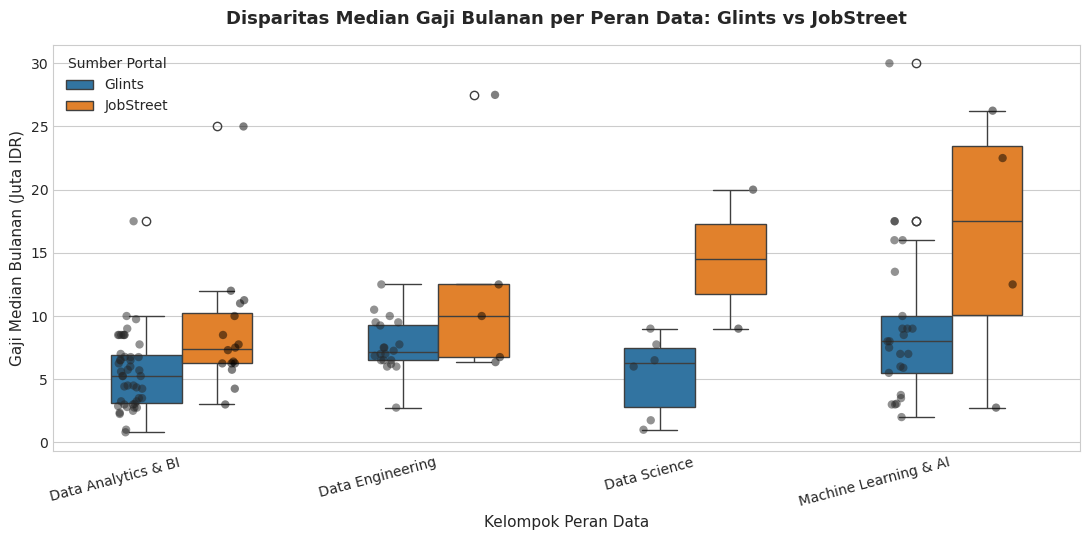

Visualisasi verifikasi tersimpan di:
  - master_br01_source_and_role_distribution.png
  - master_br02_national_top_skills.png
  - master_br03_salary_by_role_and_source.png


In [9]:
# 1. Gambar 1: Sebaran Peran per Portal & Kelompok Wilayah
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Crosstab peran vs portal
role_source = pd.crosstab(df_jobs_master['role_group'], df_jobs_master['source'])
role_source.plot(kind='bar', ax=axes[0], color=['#1f77b4', '#ff7f0e'], width=0.6, edgecolor='white')
axes[0].set_title("Komposisi Peran Data: Glints vs JobStreet", fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel("Jumlah Lowongan", fontsize=10)
axes[0].set_xlabel("Kelompok Peran Data", fontsize=10)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=20, ha='right')
axes[0].legend(title="Portal Sumber")

# Donut sebaran wilayah makro
reg_counts = df_jobs_master['regional_group'].value_counts()
reg_colors = ['#2b5c8f', '#41b6c4', '#7fcdbb', '#c7e9b4', '#ffffcc', '#fd8d3c']
axes[1].pie(reg_counts.values, labels=reg_counts.index, autopct='%1.1f%%',
            startangle=140, colors=reg_colors[:len(reg_counts)],
            wedgeprops=dict(width=0.45, edgecolor='w'))
axes[1].set_title("Distribusi Geografis Pasar Kerja Data (Regional)", fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
fig1_path = FIGURES_DIR / "master_br01_source_and_role_distribution.png"
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()

# 2. Gambar 2: Top 15 Keahlian Teknis Paling Dicari Nasional
plt.figure(figsize=(10, 6.5))
top_skills_nat = df_skills_master.groupby('skill_name')['job_id'].nunique().sort_values(ascending=False).head(15)
skill_nat_pct = (top_skills_nat / len(df_jobs_master) * 100).round(1)

bars = plt.barh(top_skills_nat.index[::-1], top_skills_nat.values[::-1], color='#2c7fb8', height=0.65)
plt.title(f"Top 15 Keahlian Teknis Pasar Kerja Data Indonesia (N={len(df_jobs_master)} Lowongan)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Jumlah Lowongan yang Mensyaratkan", fontsize=11)

for bar, pct in zip(bars, skill_nat_pct.values[::-1]):
    plt.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height()/2,
             f"{int(bar.get_width())} ({pct}%)", va='center', fontsize=9, fontweight='bold')

plt.xlim(0, max(top_skills_nat.values) + 8)
plt.tight_layout()
fig2_path = FIGURES_DIR / "master_br02_national_top_skills.png"
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()

# 3. Gambar 3: Distribusi Median Gaji Bulanan per Peran & Sumber
sal_master = df_jobs_master.dropna(subset=['salary_median']).copy()
sal_master['salary_median_jt'] = sal_master['salary_median'] / 1e6

plt.figure(figsize=(11, 5.5))
sns.boxplot(data=sal_master, x='role_group', y='salary_median_jt', hue='source', palette=['#1f77b4', '#ff7f0e'], width=0.55)
sns.stripplot(data=sal_master, x='role_group', y='salary_median_jt', hue='source', dodge=True, color='black', alpha=0.5, size=6)

plt.title("Disparitas Median Gaji Bulanan per Peran Data: Glints vs JobStreet", fontsize=13, fontweight='bold', pad=15)
plt.ylabel("Gaji Median Bulanan (Juta IDR)", fontsize=11)
plt.xlabel("Kelompok Peran Data", fontsize=11)
plt.xticks(rotation=15, ha='right')

# Rapikan legend
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:2], labels[:2], title="Sumber Portal")

plt.tight_layout()
fig3_path = FIGURES_DIR / "master_br03_salary_by_role_and_source.png"
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Visualisasi verifikasi tersimpan di:")
print(f"  - {fig1_path.name}")
print(f"  - {fig2_path.name}")
print(f"  - {fig3_path.name}")

### Sel 10: Ekspor Dataset Final Layer Master (CSV & Parquet)

In [10]:
# Path ekspor CSV dan Parquet
jobs_master_csv = PROCESSED_DATA_DIR / "jobs_master.csv"
jobs_master_parquet = PROCESSED_DATA_DIR / "jobs_master.parquet"

skills_master_csv = PROCESSED_DATA_DIR / "skills_master.csv"
skills_master_parquet = PROCESSED_DATA_DIR / "skills_master.parquet"

# Pastikan konsistensi tipe data kolom string sebelum ekspor Parquet
str_cols = [
    'job_id', 'source', 'source_job_id', 'job_url', 'title_raw',
    'role_group', 'role_standard', 'company_raw', 'province', 'city',
    'regional_group', 'work_mode', 'employment_type',
    'education_requirement', 'experience_level', 'salary_bracket', 'collected_at'
]
for col in str_cols:
    if col in df_jobs_master_export.columns:
        df_jobs_master_export[col] = df_jobs_master_export[col].fillna('').astype(str)

for col in ['job_id', 'source', 'role_group', 'skill_name', 'skill_category']:
    if col in df_skills_master.columns:
        df_skills_master[col] = df_skills_master[col].fillna('').astype(str)

# Ekspor Master Jobs
df_jobs_master_export.to_csv(jobs_master_csv, index=False, encoding="utf-8")
df_jobs_master_export.to_parquet(jobs_master_parquet, index=False)

# Ekspor Master Skills
df_skills_master.to_csv(skills_master_csv, index=False, encoding="utf-8")
df_skills_master.to_parquet(skills_master_parquet, index=False)

print("Master dataset analitik berhasil diekspor:")
print(f"1. jobs_master.csv     : {jobs_master_csv.resolve()} ({len(df_jobs_master_export)} baris, {jobs_master_csv.stat().st_size / 1024:.1f} KB)")
print(f"2. jobs_master.parquet : {jobs_master_parquet.resolve()} ({jobs_master_parquet.stat().st_size / 1024:.1f} KB)")
print(f"3. skills_master.csv   : {skills_master_csv.resolve()} ({len(df_skills_master)} baris, {skills_master_csv.stat().st_size / 1024:.1f} KB)")
print(f"4. skills_master.parquet: {skills_master_parquet.resolve()} ({skills_master_parquet.stat().st_size / 1024:.1f} KB)")
print("\n[SELESAI] Data master telah siap digunakan untuk analisis eksploratif mendalam maupun visualisasi dashboard interaktif.")

Master dataset analitik berhasil diekspor:
1. jobs_master.csv     : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed\jobs_master.csv (250 baris, 97.8 KB)
2. jobs_master.parquet : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed\jobs_master.parquet (47.3 KB)
3. skills_master.csv   : C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed\skills_master.csv (1061 baris, 87.7 KB)
4. skills_master.parquet: C:\Users\Victus 16\data-project\analisi_loker_data_indonesia\data\processed\skills_master.parquet (10.8 KB)

[SELESAI] Data master telah siap digunakan untuk analisis eksploratif mendalam maupun visualisasi dashboard interaktif.
